In [1]:
import pandas as pd
import numpy as np

## Данные соревнования МТС: https://ods.ai/competitions/competition-recsys-21/data

In [3]:
!curl -O https://storage.yandexcloud.net/datasouls-ods/materials/04adaecc/interactions.csv

  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed

  0      0   0      0   0      0      0      0           00:01              0
  2 171.6M   2  4.63M   0      0  1.93M      0   01:28   00:02   01:26  4.55M
  9 171.6M   9 15.96M   0      0  4.69M      0   00:36   00:03   00:33  7.88M
 17 171.6M  17 29.88M   0      0  6.76M      0   00:25   00:04   00:21  9.83M
 24 171.6M  24 41.51M   0      0  6.94M      0   00:24   00:05   00:19  9.01M
 31 171.6M  31 53.86M   0      0  7.60M      0   00:22   00:07   00:15  9.43M
 41 171.6M  41 70.72M   0      0  7.97M      0   00:21   00:08   00:13 10.20M
 48 171.6M  48 83.07M   0      0  8.11M      0   00:21   00:10   00:11  9.81M
 54 171.6M  54 93.41M   0      0  8.29M      0   00:20   00:11   00:09  9.27M
 62 171.6M  62 106.8M   0      0  8.71M      0   00:19   00:12   00:07 10.40M
 69 171.6M  69 118.7M   0      0  8.95M      0   00:19   00:13 

In [2]:
df = pd.read_csv("interactions.csv")
df.head()

,user_id,item_id,last_watch_dt,total_dur,watched_pct
0,176549,9506,2021-05-11,4250,72.0
1,699317,1659,2021-05-29,8317,100.0
2,656683,7107,2021-05-09,10,0.0
3,864613,7638,2021-07-05,14483,100.0
4,964868,9506,2021-04-30,6725,100.0


In [3]:
df["last_watch_dt"] = pd.to_datetime(df["last_watch_dt"]) - pd.to_datetime(df["last_watch_dt"]).min()
df["last_watch_dt"] = df.last_watch_dt.apply(lambda x: int(str(x).split()[0]))
df.sample(5)

,user_id,item_id,last_watch_dt,total_dur,watched_pct
3269683,831033,9335,39,4770,88.0
3308763,343093,13463,73,5960,100.0
5376387,596966,16021,121,173,2.0
1639075,223220,7189,141,2271,36.0
4683373,421141,9006,161,4655,67.0


In [4]:
df.shape, df['user_id'].nunique(), df['item_id'].nunique()

((5476251, 5), 962179, 15706)

<Axes: >

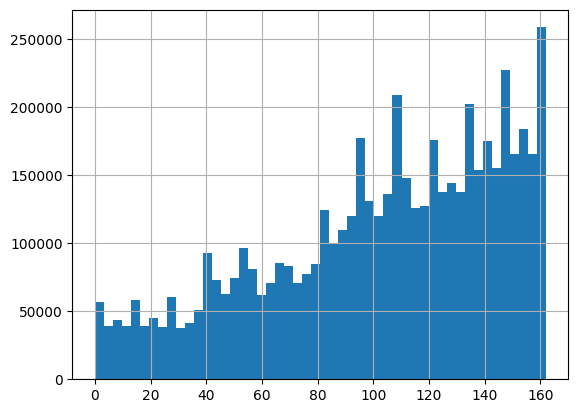

In [5]:
df['last_watch_dt'].hist(bins=50)

In [6]:
max_watch_dt = df['last_watch_dt'].max()
max_watch_dt

np.int64(162)

#### Разобьем датасет на трейн и тест. в тест отправим все события за последние 30 дней, в трейн все остальное. Посчитаем число уникальных юзеров в трейне и тесте, и юзеров, которые есть и там и там. Затем оставим в тесте только тех юзеров/айтемы, которые есть в трейне

In [7]:
test_df = df[df['last_watch_dt'] >= max_watch_dt - 30].copy()
train_df = df[df['last_watch_dt'] < max_watch_dt - 30].copy()

assert train_df.shape[0] == 3740952
assert test_df.shape[0] == 1735299 

In [8]:
old_shape = test_df.shape[0]

user_test = set(test_df['user_id'].unique())
user_train = set(train_df['user_id'].unique())
users = user_test & user_train
test_df = test_df[test_df['user_id'].isin(users) & test_df['item_id'].isin(train_df['item_id'].unique())].copy()


assert test_df.shape[0] == 851974
assert test_df['user_id'].nunique() == 186701
assert test_df['item_id'].nunique() == 8867


print(f"Размер тестовой выборки после фильтрации: {test_df.shape[0]} (было удалено {old_shape - test_df.shape[0]} строк или {100 * (old_shape - test_df.shape[0]) / old_shape:.2f}%)")
print(f"Число уникальных пользователей в тестовой выборке: {test_df.user_id.nunique()}")

Размер тестовой выборки после фильтрации: 851974 (было удалено 883325 строк или 50.90%)
Число уникальных пользователей в тестовой выборке: 186701


#### Насэмплируем 50_000 юзеров которые есть и в трейне и в тесте и ограничим тестовую и трейновую выборку только этими пользователями

In [9]:
np.random.seed(42)
train_users = train_df['user_id'].unique()
test_users = test_df.user_id.unique()
n_users = 40_000

users = np.intersect1d(train_users, test_users)
sampled_users = np.random.choice(users, n_users, replace=False)

test_df = test_df[test_df['user_id'].isin(sampled_users)].copy()
train_df = train_df[train_df['user_id'].isin(sampled_users)].copy()

assert train_df['last_watch_dt'].max() < test_df['last_watch_dt'].min()
assert train_df['user_id'].nunique() == n_users
assert test_df['user_id'].nunique() == n_users

In [10]:
train_items = train_df['item_id'].unique()
test_df = test_df[test_df['item_id'].isin(train_items)].copy()

In [11]:
print(train_df['user_id'].nunique(), train_df['item_id'].nunique())
print(test_df['user_id'].nunique(), test_df['item_id'].nunique())
print(train_df.shape, test_df.shape)

40000 9185
39933 5732
(384043, 5) (180750, 5)


In [12]:
def ndcg_metric(gt_items, predicted):
    at = len(predicted)
    relevance = np.array([1 if x in predicted else 0 for x in gt_items])
    # DCG uses the relevance of the recommended items
    rank_dcg = dcg(relevance)

    if rank_dcg == 0.0:
        return 0.0

    # IDCG has all relevances to 1 (or the values provided), up to the number of items in the test set that can fit in the list length
    ideal_dcg = dcg(np.sort(relevance)[::-1][:at])

    if ideal_dcg == 0.0:
        return 0.0

    ndcg_ = rank_dcg / ideal_dcg

    return ndcg_


def dcg(scores):
    return np.sum(
        np.divide(np.power(2, scores) - 1, np.log2(np.arange(scores.shape[0], dtype=np.float64) + 2)), dtype=np.float64
    )


def recall_metric(gt_items, predicted):

    n_gt = len(gt_items)
    intersection = len(set(gt_items).intersection(set(predicted)))
    return intersection / n_gt


def evaluate_recommender(df, model_preds, gt_col="test_interactions", topn=10):
    metric_values = []

    for idx, row in df.iterrows():
        gt_items = row[gt_col]
        metric_values.append((ndcg_metric(gt_items, row[model_preds]), recall_metric(gt_items, row[model_preds])))

    return {"ndcg": np.mean([x[0] for x in metric_values]), "recall": np.mean([x[1] for x in metric_values])}

In [13]:
test_df_grouped = test_df.groupby('user_id').apply(lambda x: list(x['item_id']), include_groups=False).reset_index(name='test_interactions')
test_df_grouped.head()

,user_id,test_interactions
0,3,"[12192, 9728, 16406, 15719, 10440, 3475, 2025,..."
1,53,"[1445, 4151, 12250, 15629, 3734, 16426, 15810,..."
2,98,"[4689, 512, 5051]"
3,106,"[14619, 12908, 10544, 6267, 13463, 5411, 2836,..."
4,155,"[8101, 5077, 281, 9006]"


### ALS

Итак, поставлена задача построения модели со скрытыми переменными (latent factor model) для коллаборативной фильтрации:

$$\sum_{u,i} (r_{ui} - \langle p_u, q_i \rangle)^2 \to \min_{P,Q}. $$

Напомним, что суммирование ведется по всем парам $(u, i),$ для которых известен рейтинг $r_{ui}$ (и только по ним), а $p_u, q_i$ – латентные представления пользователя $u$ и товара $i$ из соответствующих матрицы $P, Q$.

Подход ALS (Alternating Least Squares) решает задачу, попеременно фиксируя матрицы $P$ и $Q$, — оказывается, что, зафиксировав одну из матриц, можно выписать аналитическое решение задачи для другой.

$$\nabla_{p_u} \bigg[ \sum_{u,i} (r_{ui} - \langle p_u, q_i \rangle)^2 \bigg] = \sum_{i} 2(r_{ui} - \langle p_u, q_i \rangle)q_i = 0$$

Воспользовавшись тем, что $a^Tbc = cb^Ta$, получим
$$\sum_{i} r_{ui}q_i - \sum_i q_i q_i^T p_u = 0.$$
Тогда окончательно каждый столбец матрицы $P$ можно найти по формуле
$$p_u = \bigg( \sum_i q_i q_i^T\bigg)^{-1}\sum_ir_{ui}q_i \;\; \forall u,$$
аналогично для столбцов матрицы $Q$
$$q_i = \bigg( \sum_u p_u p_u^T\bigg)^{-1}\sum_ur_{ui}p_u \;\; \forall i.$$

Таким образом мы можем решать оптимизационную задачу, поочередно фиксируя одну из матриц $P$ или $Q$ и проводя оптимизацию по второй.

**Оригинальная статья (для explicit feedback):**

Bell, R.M. and Koren, Y., 2007, October. Scalable collaborative filtering with jointly derived neighborhood interpolation weights. In Seventh IEEE international conference on data mining (ICDM 2007) (pp. 43-52). IEEE.


### iALS


**Статья для implicit данных:**


Implicit feedback ALS:
* Hu, Y., Koren, Y. and Volinsky, C., 2008, December. Collaborative filtering for implicit feedback datasets. In 2008 Eighth IEEE international conference on data mining (pp. 263-272). Ieee. http://yifanhu.net/PUB/cf.pdf

**Особенности:**

1. Нет explicit данных (явных позитивных и отрицательных оценок). <br>
2. Много шума в данных.  <br>
3. Используются свои функции и метрики для оценки implicit feedback. Если в explicit $r_ui$ - это оценки предпочтений пользователя, то в implicit - это степень уверенности. <br>


| Критерий | ALS  |  iALS | 
|---|---|---|
| Тип данных | Этот подход используется, когда у вас есть явные рейтинги или оценки, предоставленные пользователями для различных предметов. Например, пользователи могут оценивать фильмы по шкале от 1 до 5. |  Этот подход используется, когда у вас есть неявные сигналы взаимодействия между пользователями и предметами, такие как клики, просмотры, покупки или временные интервалы между действиями. |  
|
|Цель | Модель стремится точно предсказать явные рейтинги или оценки, которые пользователи могли бы дать предметам. | Модель стремится моделировать уровень уверенности или важности взаимодействия между пользователем и предметом, но не предсказывает явные рейтинги.|  
|
|Функции потерь| Обычно использует функцию потерь, такую как среднеквадратичная ошибка (MSE), для минимизации разницы между предсказанными и фактическими оценками. | Использует функцию потерь, которая учитывает уверенность в неявных взаимодействиях и стремится увеличить уверенность для более важных взаимодействий.| 
|
|Взвешивание| Не уделяет внимания взаимодействиям, которые не были явно оценены пользователями. Исключает информацию о неявных действиях. | Дополнительная параметризация. Учитывает все неявные действия, но с учетом их уверенности или веса, что позволяет модели учесть важность различных видов взаимодействий| 
|

Библиотека implicit: https://benfred.github.io/implicit/

In [14]:
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import LabelEncoder
from tqdm.auto import tqdm

class NaiveALS:
    def __init__(self, n_iters, n_factors, reg=0):
        self.reg = reg
        self.n_iters = n_iters
        self.n_factors = n_factors

    def fit(self, train: pd.DataFrame, test: pd.DataFrame):
        n_users = train["user_id"].nunique()
        m_items = train["item_id"].nunique()

        self.user_encoder = LabelEncoder()
        self.item_encoder = LabelEncoder()

        encoded_users = self.user_encoder.fit_transform(train_df["user_id"].values)
        encoded_item = self.item_encoder.fit_transform(train_df["item_id"].values)

        train_ratings = np.zeros((n_users, m_items))
        train_ratings[encoded_users, encoded_item] = 1
        print(train_ratings.shape)

        self.P = np.random.rand(n_users, self.n_factors)
        self.Q = np.random.rand(m_items, self.n_factors)

        for i in tqdm(range(self.n_iters)):
            self.P = self._als_step(train_ratings, self.P, self.Q)
            self.Q = self._als_step(train_ratings.T, self.Q, self.P)

            pred = self.predict()
            print(f'{i})  MSE=[{self.compute_mse(train_ratings, pred)}]')

    def _als_step(self, ratings, solve_vecs, fixed_vecs):

        part_r = np.linalg.inv(fixed_vecs.T @ fixed_vecs + self.reg * np.eye(self.n_factors))
        result = ratings @ fixed_vecs @ part_r
        
        return result 
        

    def predict(self):
        pred = self.P.dot(self.Q.T)
        return pred

    def get_top_k_predicts(self, k: int) -> pd.DataFrame:
        pred_scores = self.predict()
        n_users = pred_scores.shape[0]

        user_ids = self.user_encoder.inverse_transform(np.arange(n_users))
        top_k_indices = (-pred_scores).argsort(axis=1)[:, :k]
        top_k_items = [
            self.item_encoder.inverse_transform(row_indices).tolist() 
            for row_indices in top_k_indices
        ]
        df_pred = pd.DataFrame({
            'user_id': user_ids, 
            'naive_als_pred': top_k_items
        })

        return df_pred
        
        
    @staticmethod
    def compute_mse(y_true, y_pred):
        mask = np.nonzero(y_true)
        mse = mean_squared_error(y_true[mask], y_pred[mask])
        return mse

In [15]:
naive_als = NaiveALS(n_iters=10, n_factors=16, reg=0.01)
naive_als.fit(train_df, test_df)

(40000, 9185)


  0%|          | 0/10 [00:00<?, ?it/s]

0)  MSE=[0.8686434115900239]
1)  MSE=[0.7581860752645755]
2)  MSE=[0.7489649814488253]
3)  MSE=[0.7463248278121447]
4)  MSE=[0.7450887466202115]
5)  MSE=[0.7444126674443164]
6)  MSE=[0.7440069552210354]
7)  MSE=[0.7437492737326552]
8)  MSE=[0.7435880289793168]
9)  MSE=[0.7434960685885655]


In [17]:
preds = naive_als.get_top_k_predicts(k=50)
test_df_grouped["als_recs_naive"] = preds['naive_als_pred']
evaluate_recommender(test_df_grouped, model_preds="als_recs_naive")

{'ndcg': np.float64(0.2509963403914596),
 'recall': np.float64(0.15687319330317478)}

In [18]:
from typing import List

from scipy.sparse import csr_matrix
from implicit.als import AlternatingLeastSquares
from implicit.bpr import BayesianPersonalizedRanking

from sklearn.metrics import mean_squared_error


class ImplicitModel:
    def __init__(self, model):
        self.model = model
        self.trained = False

    def fit(self, train_df: pd.DataFrame):
        self.item_encoder = LabelEncoder()
        self.user_encoder = LabelEncoder()
        self.item_encoder.fit(train_df.item_id)
        self.user_encoder.fit(train_df.user_id)

        self.train_ratings = self.encode_table(train_df, ["user_id", "item_id"])
        self.model.fit(self.train_ratings)
        self.trained = True

    def predict(self, test_df: pd.DataFrame, top_k: int = 100):
        if not self.trained:
            raise ValueError("Model is not fitted. Please, fit the model first")
        users_to_predict = test_df.user_id
        encoded_users = self.user_encoder.transform(users_to_predict)
        user_recs = self.model.recommend(
            encoded_users, self.train_ratings[encoded_users], N=top_k, filter_already_liked_items=True
        )[0]
        recs = [self.item_encoder.inverse_transform(x) for x in user_recs]
        return recs

    def encode_table(self, df: pd.DataFrame, axis_names: List[str]) -> np.ndarray:
        user_ids = self.user_encoder.transform(df[axis_names[0]])
        item_ids = self.item_encoder.transform(df[axis_names[1]])

        matrix_shape = len(self.user_encoder.classes_), len(self.item_encoder.classes_)

        sparse = csr_matrix((np.ones(len(user_ids)), (user_ids, item_ids)), shape=matrix_shape, dtype=np.float32)

        return sparse

In [19]:
als = AlternatingLeastSquares(iterations=10, factors=16, regularization=0.01, calculate_training_loss=True)
als_recommender = ImplicitModel(als)
als_recommender.fit(train_df)

c:\Users\A1ex5\Desktop\CodeFlow\.venv\Lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 12 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


  0%|          | 0/10 [00:00<?, ?it/s]

In [20]:
preds = als_recommender.predict(test_df_grouped, top_k=50)
test_df_grouped["als_recs"] = preds
evaluate_recommender(test_df_grouped, model_preds="als_recs")

{'ndcg': np.float64(0.31983693998845475),
 'recall': np.float64(0.2033264913224818)}

In [21]:
user_encoder = LabelEncoder().fit(train_df["user_id"])
item_encoder = LabelEncoder().fit(train_df["item_id"])

In [22]:
import torch
import torch.nn as nn

In [23]:
train_encoded_users = torch.Tensor(user_encoder.transform(train_df["user_id"].values)).long()
train_encoded_items = torch.Tensor(item_encoder.transform(train_df["item_id"].values)).long()

In [24]:
user_encoder = LabelEncoder().fit(train_df["user_id"])
item_encoder = LabelEncoder().fit(train_df["item_id"])

In [25]:
def transform(x):
    encoded = item_encoder.transform(x)
    return encoded.tolist()

user_interactions = train_df.groupby(["user_id"]).agg({"item_id": transform})
user_interactions

,item_id
user_id,
3,"[2084, 1461]"
53,"[857, 8958, 7717, 903, 4223, 8533, 3686, 5853,..."
98,"[2526, 68, 1332, 920, 1142, 4627, 2776, 2666, ..."
106,"[1751, 5276, 151, 2652, 3802, 1998, 1404, 8989..."
155,"[7743, 198, 2640, 5121]"
...,...
1097454,[5806]
1097470,"[5109, 2516, 8236, 1067, 4598, 8816, 8037, 490..."
1097479,"[5121, 2084, 2666, 5981, 2266]"


In [26]:
from torch import Tensor


class NCF(torch.nn.Module):
    def __init__(self, n_users: int, m_items: int, n_factors: int, hidden_dim: int) -> None:
        super().__init__()
        self.n_users = n_users
        self.m_items = m_items
        self.n_factors = n_factors
        self.hidden_dim = hidden_dim

        self.user_embedding = nn.Embedding(n_users, n_factors)
        self.item_embedding = nn.Embedding(m_items, n_factors)

        self.seq = nn.Sequential(
            nn.Linear(n_factors * 2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()
        )
        

    def forward(self, item: Tensor, user: Tensor) -> torch.tensor:
        user_e = self.user_embedding(user)
        item_e = self.item_embedding(item)

        data = torch.cat([user_e, item_e], dim=-1)
        prediction = self.seq(data)
        
        return prediction

In [27]:
ncf_model = NCF(n_users=len(user_encoder.classes_), m_items=len(item_encoder.classes_), n_factors=16, hidden_dim=64)
ncf_model

NCF(
  (user_embedding): Embedding(40000, 16)
  (item_embedding): Embedding(9185, 16)
  (seq): Sequential(
    (0): Linear(in_features=32, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
    (3): Sigmoid()
  )
)

In [28]:
optimizer = torch.optim.SGD(ncf_model.parameters(), lr=1e-4)
loss = nn.BCELoss()

all_items = set(list(range(ncf_model.m_items)))

for user, item in tqdm(zip(train_encoded_users, train_encoded_items), total=len(train_encoded_users)):
    optimizer.zero_grad()
    # сэмплируем негативы для пользователя из айтемов, с которыми он не взаимодействовал
    seen_items = set(user_interactions.loc[user_encoder.inverse_transform([user.item()])])
    unseen_items = list(all_items - seen_items)
    neg_item = torch.Tensor(np.array([np.random.choice(unseen_items, size=1)])).long()[0][0]

    # считаем скор позитивного взаимодействия
    pos_prediction = ncf_model(item, user)
    # считаем скор негативного взаимодействия
    neg_prediction = ncf_model(neg_item, user)

    # лосс для каждого из типов взаимодействий
    cur_loss = loss(pos_prediction, torch.Tensor([1]).float())
    cur_loss += loss(neg_prediction, torch.Tensor([0]).float())

    cur_loss.backward()
    optimizer.step()

  0%|          | 0/384043 [00:00<?, ?it/s]

#### Реализовать инференс модели и подсчет метрик

In [29]:
ncf_model.eval()

count_class_item = len(item_encoder.classes_)

item_t = torch.arange(0, count_class_item, dtype=torch.long)

In [30]:
user_id = test_df_grouped['user_id'].iloc[0]
test_interactions = test_df_grouped['test_interactions'].iloc[0]

user_c = user_encoder.transform([user_id])[0]
user_t = torch.Tensor([user_c]).long()
user_t_r = torch.repeat_interleave(user_t, count_class_item)

pred = ncf_model(item_t, user_t_r)
pred = pred.squeeze(1).detach().numpy()

print(pred)

[0.4599783  0.48154044 0.43187052 ... 0.5053931  0.5010594  0.6046264 ]


In [42]:
see_items = user_interactions['item_id'].loc[user_id]
pred[see_items] = -np.inf
pred[2084]

np.float32(-inf)

In [32]:
pred_sort = np.argsort(pred)[::-1]
pred_sort[:50]

array([8533, 5465, 5220,  218, 6624, 5570, 8839, 7208, 3163, 7537, 7279,
       1592, 4632, 8509, 1193, 4202, 6373,  755, 4638, 6224, 8594, 4237,
       4200, 1875, 1664,  911, 2588, 8799, 1613, 7097, 3507, 4085, 2238,
       6328,  244, 5521, 3530, 1093, 5630, 5842, 3195,  647,  225, 1263,
       6462, 4663, 3940, 8877, 7236,  111])

In [34]:
recommendations = []


for i in tqdm(range(len(test_df_grouped['user_id']))):
    user_id = test_df_grouped['user_id'].iloc[i]
    test_interactions = test_df_grouped['test_interactions'].iloc[i]

    user_c = user_encoder.transform([user_id])[0]
    user_t = torch.Tensor([user_c]).long()
    user_t_r = torch.repeat_interleave(user_t, count_class_item)

    pred = ncf_model(item_t, user_t_r)
    pred = pred.squeeze(1).detach().numpy()

    see_items = user_interactions['item_id'].loc[user_id]
    pred[see_items] = -np.inf
    pred_sort = np.argsort(pred)[::-1]

    top_50 = item_encoder.inverse_transform(pred_sort[:50])

    recommendations.append(top_50)


  0%|          | 0/39933 [00:00<?, ?it/s]

In [35]:
test_df_grouped["ncf_recs"] = recommendations
evaluate_recommender(test_df_grouped, model_preds="ncf_recs")

{'ndcg': np.float64(0.0836306061813813),
 'recall': np.float64(0.04844649549399929)}